# 05 · Phân tích hồi cứu ca thật

> Đọc bộ rà soát do run tạo (top 10 + 10 ngẫu nhiên trong các ca test còn lại, xếp hạng theo phương pháp đề xuất). Notebook này **mở khóa** bảng ánh xạ
> (điểm, hạng) để phân tích; bảng gửi người rà soát (`case_review_blinded.csv`) không có điểm/hạng/mô hình.

**Câu hỏi.**
1. Nhóm điểm cao khác nhóm ngẫu nhiên thế nào (nhánh DONE/Rejected, độ dài)? Tất cả Rejected có phải lỗi không?
2. Với từng ca: lịch sử gốc, event còn lại trong core, chuyển tiếp có surprisal cao, đoạn lặp, độ phủ OOV.
3. Đã có ai rà soát chưa? Có bất đồng giữa người rà soát không?

**Giới hạn đọc kết quả.** Bằng chứng ở đây *mô tả hành vi* so với đồ thị train. Không được viết ‘Isolation Forest cảnh báo vì X’ chỉ vì có một bảng thống kê X;
điểm cao **không** đồng nghĩa vi phạm quy trình. Nếu agent là người phân tích, đó là reviewer *khám phá*, không phải nhãn chuyên gia.

In [1]:
# Khởi tạo: mở run đã kiểm fingerprint (biến môi trường JIRA_AD_RUN_DIR do `jira-ad notebooks` đặt).
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from jira_ad.analysis import open_run

pd.options.display.float_format = "{:.3f}".format
pd.options.display.max_colwidth = 90
run = open_run()
print(run.header())

run_id      : 20261017T081309Z-930f8a85  (status: completed)
chọn run    : tự động: run hoàn tất mới nhất khớp configs/baseline.yaml hiện tại (đặt JIRA_AD_RUN_DIR để chọn run khác)
config_hash : 930f8a856d4a…  config: configs/experiments.yaml
split_hash  : a3999ae50439…  action_rules: 4a35ef7d0f48…
đầu vào     : dataset/TIeventlogBug.csv sha256=cda16f1c5c4a…; configs/actions.yaml sha256=4a35ef7d0f48…
seeds       : {'split': 42, 'model': 42, 'validation_mutation': 1042, 'test_mutation': 2042}  | cohort: bug  | methods: ['A_stats', 'B_ngrams', 'C_embedding', 'D_hybrid']


In [2]:
from jira_ad import plots
from jira_ad.analysis import REVIEW_LABELS, case_event_table
from jira_ad.data import load_raw_events
from jira_ad.preprocess import build_core_view, load_action_rules, normalize_events

cfg = run.cfg
key = run.read_csv("case_review_key.csv")
blinded = run.read_csv("case_review_blinded.csv").fillna("")
evidence = run.read_json("tables/case_evidence.json")
splits = run.read_csv("split_manifest.csv").set_index("case_id")
method = key.method.iloc[0]
scores = run.read_parquet("scores/originals.parquet")
primary = scores[(scores.method == method) & (scores.split == "test")].set_index("trace_id")

rules = load_action_rules(cfg.preprocess.actions_path)
events = normalize_events(load_raw_events(cfg.data, run.project_root), cfg.preprocess, rules)   # full view
traces = {t.trace_id: t for t in build_core_view(events, cfg.preprocess, rules).traces}
print(f"Xếp hạng theo {method} trên {len(primary)} ca test; bộ rà soát {len(key)} ca "
      f"({int((key.group == 'top').sum())} điểm cao + {int((key.group == 'random').sum())} ngẫu nhiên).")

Xếp hạng theo D_hybrid trên 31 ca test; bộ rà soát 20 ca (10 điểm cao + 10 ngẫu nhiên).


## 1. Nhóm điểm cao so với nhóm ngẫu nhiên

In [3]:
review = key.assign(terminal_status=key.case_id.map(splits.terminal_status),
                    n_events=key.case_id.map(primary.n_events))
test_all = primary.join(splits.terminal_status)
composition = pd.crosstab(review.group, review.terminal_status)
composition.loc["tất cả ca test"] = test_all.terminal_status.value_counts()
run.save_table(composition.reset_index(), "nb05_composition")
display(composition)
length = review.groupby("group").n_events.median().to_dict()
length["tất cả ca test"] = float(primary.n_events.median())
display(pd.Series(length, name="trung vị n_events").to_frame())

terminal_status,DONE,Rejected
group,,
random,6,4
top,4,6
tất cả ca test,16,15


,trung vị n_events
random,25.000
top,15.500
tất cả ca test,18.000


## 2. Từng ca: lịch sử, core, chuyển tiếp đáng chú ý

### R06 · `bug:TI-5412` · nhóm **top** · hạng 1/31 · điểm 0.5214 · kết cục `DONE` · 61 event core

**Chuỗi (core):** CREATE [PO] → ADD_ISSUE_LINK [unknown] → EDIT_DESCRIPTION [PO] → ADD_ISSUE_LINK [PO] → UPDATE_PROJECT [PO] → REMOVE_ASSIGNEE [unknown] → UPDATE_BACKLOG_CLASSIFICATION [unknown] → EDIT_SUMMARY [PO] → STATUS_To Investigate [PO] → ADD_ISSUE_LINK [unknown] → EDIT_DESCRIPTION [unknown] → ADD_FIX_VERSION [PO] → UPDATE_BLOCKING_FOR_RELEASE [PO] → EDIT_ISSUEPARENTASSOCIATION [PO] → ADD_EPIC_LINK [PO] → LINK_COMMIT [bot] → LINK_MERGE_REQUEST [bot] → EDIT_DESCRIPTION [Eng] → ADD_ATTACHMENT [Eng] → ADD_ATTACHMENT [Eng] → ADD_ATTACHMENT [Eng] → ADD_ATTACHMENT [Eng] → ADD_ATTACHMENT [Eng] → ADD_ATTACHMENT [Eng] → LINK_COMMIT [bot] → LINK_MERGE_REQUEST [bot] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → EDIT_DESCRIPTION [Eng] → EDIT_DESCRIPTION [Eng] → EDIT_DESCRIPTION [Eng] → STATUS_INVESTIGATED [unknown] → EDIT_DESCRIPTION [Eng] → ADD_ISSUE_LINK [Eng] → STATUS_To Do [PO] → ADD_ASSIGNEE [PO] → ADD_ISSUE_LINK [Eng] → ADD_ISSUE_LINK [unknown] → ADD_STORY_POINTS [unknown] → STATUS_In Progress [unknown] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → LINK_MERGE_REQUEST [bot] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → LINK_MERGE_REQUEST [bot] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → STATUS_In Test [Eng] → STATUS_DONE [PO]

,position,source,target,surprisal,count,unseen_transition
0,7,UPDATE_BACKLOG_CLASSIFICATION,EDIT_SUMMARY,4.868,0,True
1,15,ADD_EPIC_LINK,LINK_COMMIT,4.575,0,True
2,24,ADD_ATTACHMENT,LINK_COMMIT,4.357,0,True
3,34,ADD_ISSUE_LINK,STATUS_To Do,4.193,3,False
4,8,EDIT_SUMMARY,STATUS_To Investigate,4.094,0,True


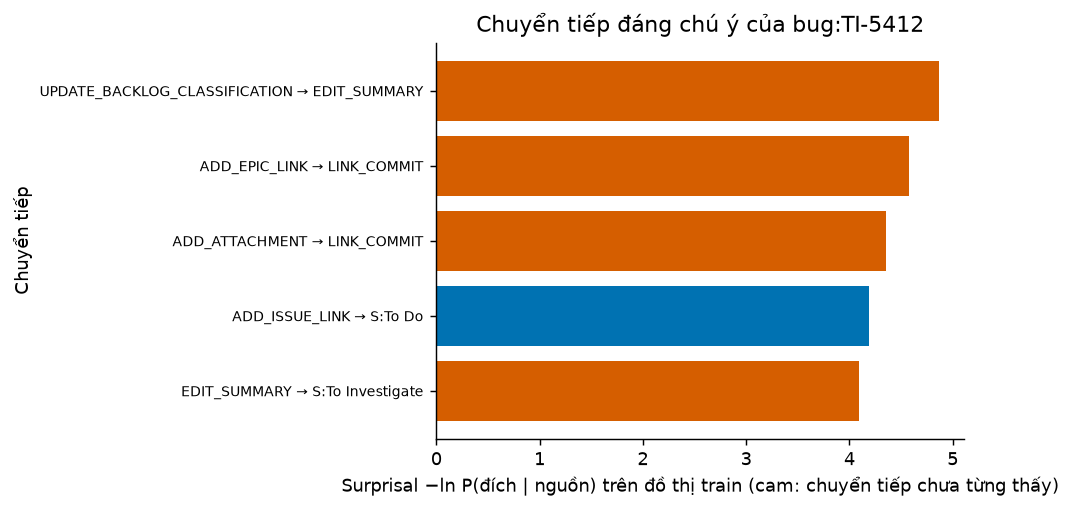

- Đoạn lặp kề nhau: [{'activity': 'ADD_ATTACHMENT', 'start': 18, 'length': 6}, {'activity': 'LINK_COMMIT', 'start': 26, 'length': 2}, {'activity': 'EDIT_DESCRIPTION', 'start': 28, 'length': 3}, {'activity': 'ADD_ISSUE_LINK', 'start': 36, 'length': 2}, {'activity': 'LINK_COMMIT', 'start': 40, 'length': 2}, {'activity': 'LINK_COMMIT', 'start': 43, 'length': 3}, {'activity': 'LINK_COMMIT', 'start': 47, 'length': 12}]
- Độ phủ: nút chưa thấy không có; 6.5% chuyển tiếp chưa từng thấy ở train
- Role: {'n_missing': 0, 'n_unknown': 9, 'n_bot': 25}
- Bằng chứng mô tả hành vi so với đồ thị train; không phải giải thích nhân quả của Isolation Forest.

**Full view:** 87 event; **26** bị bỏ khỏi core ({'noise_policy': 23, 'post_terminal': 3}).

,source_row,timestamp_utc,role,raw_action,activity,in_core,dropped_reason
0,4913,2021-11-30 07:57:48.494000+00:00,PO,Issue created,CREATE,True,
1,4999,2021-11-30 07:57:50.203000+00:00,unknown,add link to relates to,ADD_ISSUE_LINK,True,
2,4998,2021-11-30 08:00:11.021000+00:00,PO,edit description,EDIT_DESCRIPTION,True,
3,4997,2021-11-30 08:00:37.490000+00:00,PO,add link to follows,ADD_ISSUE_LINK,True,
4,4996,2021-11-30 08:01:10.929000+00:00,PO,"update project to TI-TI, edit Key",UPDATE_PROJECT,True,
5,4995,2021-11-30 08:01:14.929000+00:00,unknown,remove assignee,REMOVE_ASSIGNEE,True,
6,4994,2021-11-30 08:01:15.024000+00:00,unknown,update Backlog Classification to Technical Debt,UPDATE_BACKLOG_CLASSIFICATION,True,
7,4993,2021-11-30 08:02:04.134000+00:00,PO,edit summary,EDIT_SUMMARY,True,
8,4992,2021-11-30 12:52:01.670000+00:00,PO,update status to To Investigate,STATUS_To Investigate,True,
9,4991,2021-11-30 12:52:06.146000+00:00,unknown,add link to relates to,ADD_ISSUE_LINK,True,


### R14 · `bug:TI-5445` · nhóm **top** · hạng 2/31 · điểm 0.5173 · kết cục `Rejected` · 8 event core

**Chuỗi (core):** CREATE [unknown] → ADD_ISSUE_LINK [bot] → UPDATE_ASSIGNEE [RTE] → EDIT_REPORTER [bot] → UPDATE_PROJECT [PO] → REMOVE_ASSIGNEE [unknown] → UPDATE_BACKLOG_CLASSIFICATION [unknown] → STATUS_Rejected [PO]

,position,source,target,surprisal,count,unseen_transition
0,3,UPDATE_ASSIGNEE,EDIT_REPORTER,3.922,1,False
1,4,EDIT_REPORTER,UPDATE_PROJECT,3.277,1,False
2,2,ADD_ISSUE_LINK,UPDATE_ASSIGNEE,2.689,17,False
3,7,UPDATE_BACKLOG_CLASSIFICATION,STATUS_Rejected,2.670,8,False
4,6,REMOVE_ASSIGNEE,UPDATE_BACKLOG_CLASSIFICATION,0.997,44,False


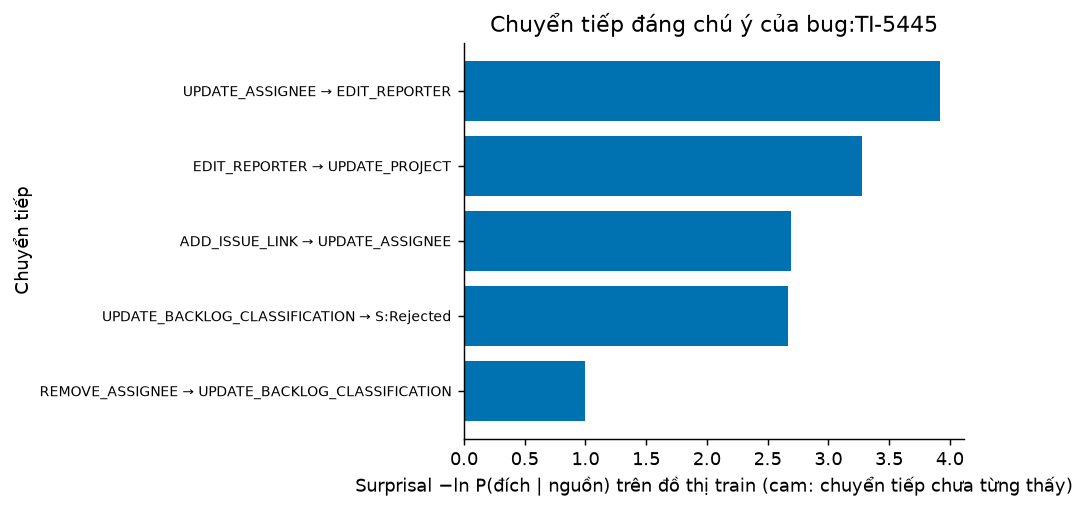

- Đoạn lặp kề nhau: không có
- Độ phủ: nút chưa thấy không có; 0.0% chuyển tiếp chưa từng thấy ở train
- Role: {'n_missing': 0, 'n_unknown': 3, 'n_bot': 2}
- Bằng chứng mô tả hành vi so với đồ thị train; không phải giải thích nhân quả của Isolation Forest.

**Full view:** 8 event; **0** bị bỏ khỏi core ({}).

,source_row,timestamp_utc,role,raw_action,activity,in_core,dropped_reason
0,4842,2021-12-01 12:26:23.173000+00:00,unknown,Issue created,CREATE,True,
1,4849,2021-12-01 12:26:23.467000+00:00,bot,add link to relates to,ADD_ISSUE_LINK,True,
2,4848,2021-12-01 12:48:35.625000+00:00,RTE,update assignee,UPDATE_ASSIGNEE,True,
3,4847,2021-12-01 12:53:25.219000+00:00,bot,edit reporter,EDIT_REPORTER,True,
4,4846,2021-12-03 10:00:41.101000+00:00,PO,"update project to TI-TI, edit Key",UPDATE_PROJECT,True,
5,4845,2021-12-03 10:00:45.513000+00:00,unknown,remove assignee,REMOVE_ASSIGNEE,True,
6,4844,2021-12-03 10:00:45.932000+00:00,unknown,update Backlog Classification to Technical Debt,UPDATE_BACKLOG_CLASSIFICATION,True,
7,4843,2021-12-08 14:24:20.091000+00:00,PO,"update resolution to Canceled, update status to Rejected",STATUS_Rejected,True,


### R11 · `bug:TI-4748` · nhóm **random** · hạng 12/31 · điểm 0.4552 · kết cục `DONE` · 51 event core

**Chuỗi (core):** CREATE [Eng] → ADD_ISSUE_LINK [unknown] → ADD_ISSUE_LINK [Eng] → UPDATE_BLOCKING_FOR_RELEASE [PM] → ADD_ISSUE_LINK [PM] → UPDATE_VERSION [PM] → ADD_FIX_VERSION [PM] → UPDATE_ASSIGNEE [RTE] → UPDATE_ASSIGNEE [RTE] → UPDATE_FIX_VERSION [PM] → UPDATE_ASSIGNEE [PM] → STATUS_To Investigate [Software Architect] → UPDATE_RANK [Software Architect] → UPDATE_BACKLOG_CLASSIFICATION [Software Architect] → UPDATE_ASSIGNEE [Software Architect] → UPDATE_FIX_VERSION [Software Architect] → REMOVE_FIX_VERSION [RTE] → STATUS_INVESTIGATED [RTE] → STATUS_To Investigate [RTE] → STATUS_INVESTIGATED [RTE] → STATUS_To Do [RTE] → STATUS_Inbox [RTE] → UPDATE_ASSIGNEE [RTE] → ADD_FIX_VERSION [RTE] → UPDATE_FIX_VERSION [PO] → REMOVE_ASSIGNEE [unknown] → STATUS_To Investigate [PO] → ADD_ISSUE_LINK [unknown] → EDIT_DESCRIPTION [unknown] → LINK_COMMIT [bot] → LINK_MERGE_REQUEST [bot] → EDIT_DESCRIPTION [Eng] → LINK_COMMIT [bot] → STATUS_INVESTIGATED [unknown] → LINK_COMMIT [bot] → STATUS_To Do [PO] → ADD_ISSUE_LINK [unknown] → ADD_STORY_POINTS [unknown] → ADD_SPRINT [PO] → REMOVE_SPRINT [PO] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → LINK_MERGE_REQUEST [bot] → STATUS_In Progress [unknown] → LINK_COMMIT [bot] → LINK_COMMIT [bot] → STATUS_In Test [Eng] → ADD_ASSIGNEE [Eng] → EDIT_ISSUEPARENTASSOCIATION [PO] → ADD_EPIC_LINK [PO] → STATUS_DONE [SQA]

,position,source,target,surprisal,count,unseen_transition
0,5,ADD_ISSUE_LINK,UPDATE_VERSION,5.580,0,True
1,14,UPDATE_BACKLOG_CLASSIFICATION,UPDATE_ASSIGNEE,4.868,0,True
2,12,STATUS_To Investigate,UPDATE_RANK,4.771,0,True
3,18,STATUS_INVESTIGATED,STATUS_To Investigate,4.771,0,True
4,35,LINK_COMMIT,STATUS_To Do,4.700,1,False


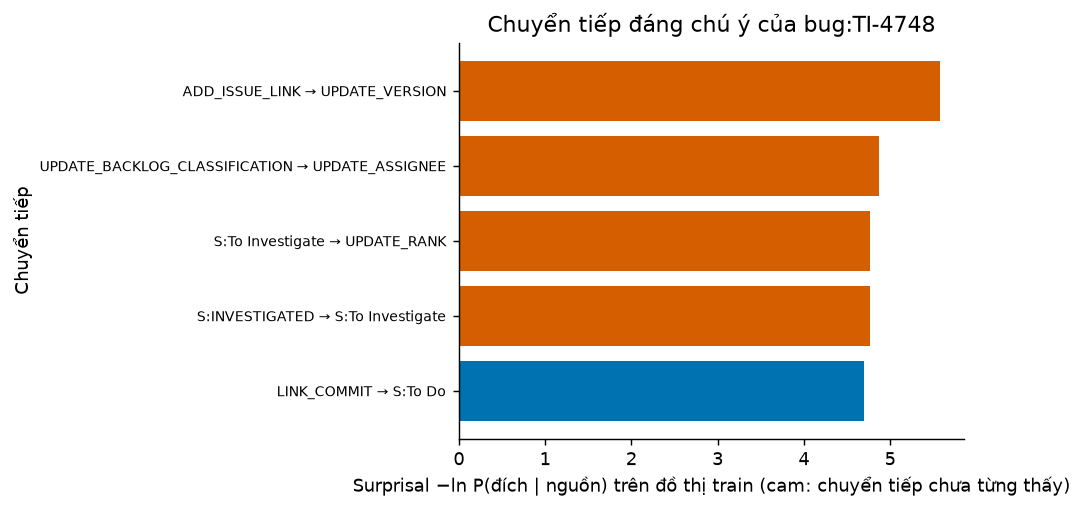

- Đoạn lặp kề nhau: [{'activity': 'ADD_ISSUE_LINK', 'start': 1, 'length': 2}, {'activity': 'UPDATE_ASSIGNEE', 'start': 7, 'length': 2}, {'activity': 'LINK_COMMIT', 'start': 40, 'length': 2}, {'activity': 'LINK_COMMIT', 'start': 44, 'length': 2}]
- Độ phủ: nút chưa thấy không có; 32.7% chuyển tiếp chưa từng thấy ở train
- Role: {'n_missing': 0, 'n_unknown': 8, 'n_bot': 9}
- Bằng chứng mô tả hành vi so với đồ thị train; không phải giải thích nhân quả của Isolation Forest.

**Full view:** 192 event; **141** bị bỏ khỏi core ({'post_terminal': 91, 'noise_policy': 50}).

,source_row,timestamp_utc,role,raw_action,activity,in_core,dropped_reason
0,2158,2021-06-25 11:24:35.351000+00:00,Eng,Issue created,CREATE,True,
1,2349,2021-06-25 11:24:37.174000+00:00,unknown,add link to relates to,ADD_ISSUE_LINK,True,
2,2348,2021-06-25 11:29:02.601000+00:00,Eng,add link to relates to,ADD_ISSUE_LINK,True,
3,2347,2021-06-25 12:15:14.259000+00:00,PM,update Blocking for Release to Yes,UPDATE_BLOCKING_FOR_RELEASE,True,
4,2346,2021-06-25 12:15:36.659000+00:00,PM,add link to relates to,ADD_ISSUE_LINK,True,
5,2345,2021-06-25 12:17:29.518000+00:00,PM,update Version,UPDATE_VERSION,True,
6,2344,2021-06-25 12:17:31.504000+00:00,PM,add Fix Version,ADD_FIX_VERSION,True,
7,2343,2021-06-28 05:59:03.871000+00:00,RTE,update assignee,UPDATE_ASSIGNEE,True,
8,2342,2021-06-28 17:38:32.076000+00:00,RTE,update assignee,UPDATE_ASSIGNEE,True,
9,2341,2021-06-29 06:49:01.953000+00:00,PM,"update Fix Version to removed, added, update project to Brno - Optics, update Version,...",UPDATE_FIX_VERSION,True,


In [4]:
def show_case(review_id):
    row = key[key.review_id == review_id].iloc[0]
    trace = traces[row.case_id]
    info = evidence[review_id]
    display(Markdown(
        f"### {review_id} · `{row.case_id}` · nhóm **{row.group}** · hạng {row['rank']}/{len(primary)} · điểm {row.anomaly_score:.4f} "
        f"· kết cục `{trace.terminal_status}` · {len(trace)} event core"
    ))
    display(Markdown(f"**Chuỗi (core):** {blinded.set_index('review_id').trace_text[review_id]}"))
    transitions = pd.DataFrame(info["transitions"])[["position", "source", "target", "surprisal", "count", "unseen_transition"]]
    display(transitions)
    fig = plots.plot_case_surprisal(info["transitions"], row.case_id)
    _ = run.show(fig, f"nb05_{review_id}_surprisal", transitions)
    display(Markdown(
        f"- Đoạn lặp kề nhau: {info['repeats'] or 'không có'}\n"
        f"- Độ phủ: nút chưa thấy {info['coverage']['unseen_tokens'] or 'không có'}; "
        f"{info['coverage']['unseen_transition_ratio']:.1%} chuyển tiếp chưa từng thấy ở train\n"
        f"- Role: {info['roles']}\n- {info['note']}"
    ))
    table = case_event_table(events, trace)
    dropped = table[~table.in_core]
    display(Markdown(f"**Full view:** {len(table)} event; **{len(dropped)}** bị bỏ khỏi core "
                     f"({dropped.dropped_reason.value_counts().to_dict()})."))
    display(table[["source_row", "timestamp_utc", "role", "raw_action", "activity", "in_core", "dropped_reason"]].head(30))

top_ids = key[key.group == "top"].sort_values("rank").review_id.head(2).tolist()
random_ids = key[key.group == "random"].sort_values("rank").review_id.head(1).tolist()
for review_id in top_ids + random_ids:
    show_case(review_id)

## 3. Rà soát của con người

In [5]:
label_columns = ["review_label", "review_reason", "reviewer"]
labelled = blinded[blinded.review_label != ""]
if labelled.empty:
    display(Markdown(
        "**Chưa có rà soát của con người** trong `case_review_blinded.csv` (cột nhãn để trống; rà soát khám phá của agent nằm riêng ở mục 3b). Vì vậy chưa có bất đồng giữa người rà soát để phân tích "
        "và chưa thể nói ca điểm cao nào ‘thật sự đáng rà soát’. Nhãn hợp lệ: `needs_review`, `plausibly_valid`, `insufficient_evidence`."
    ))
else:
    invalid = sorted(set(labelled.review_label) - set(REVIEW_LABELS))
    if invalid:
        display(Markdown(f"**Cảnh báo:** nhãn không hợp lệ {invalid}; nhãn hợp lệ là {list(REVIEW_LABELS)}."))
    display(labelled.review_label.value_counts().to_frame("số ca"))
    merged = labelled.merge(key[["review_id", "group"]], on="review_id")
    display(pd.crosstab(merged.group, merged.review_label))
    if labelled.reviewer.nunique() > 1:
        display(Markdown("Có nhiều hơn một người rà soát: kiểm tra bất đồng theo từng ca trong bảng dưới."))
        display(labelled.pivot_table(index="case_id", columns="reviewer", values="review_label", aggfunc="first"))

**Chưa có rà soát của con người** trong `case_review_blinded.csv` (cột nhãn để trống; rà soát khám phá của agent nằm riêng ở mục 3b). Vì vậy chưa có bất đồng giữa người rà soát để phân tích và chưa thể nói ca điểm cao nào ‘thật sự đáng rà soát’. Nhãn hợp lệ: `needs_review`, `plausibly_valid`, `insufficient_evidence`.

### 3b. Rà soát khám phá của agent (không phải chuyên gia nghiệp vụ)

Một agent đã gán nhãn cho 20 ca **chỉ từ bảng mù** (không điểm, hạng, mô hình hay nhóm; không mở `case_review_key.csv` hay `case_evidence.json` trước khi gán).
Căn cứ chỉ là chuỗi activity và role: không có dấu thời gian, nội dung issue hay kiến thức nghiệp vụ của đội. Đây là reviewer **khám phá** (spec §6.3), không phải nhãn chuyên gia
và không phải nhãn bất thường. File nằm ở `reviews/` của run (ngoài tập artifact đã băm, như `figures/`, `tables/`). Chỉ **sau khi có nhãn** mới ghép với nhóm (top/random).

In [6]:
from scipy.stats import fisher_exact

review_dir = run.run_dir / "reviews"
agent_files = sorted(review_dir.glob("*.csv")) if review_dir.is_dir() else []
agent = None
if not agent_files:
    display(Markdown("Chưa có file rà soát nào trong `reviews/` của run này."))
else:
    agent = pd.concat([pd.read_csv(p, dtype=str, keep_default_na=False) for p in agent_files], ignore_index=True)
    invalid = sorted(set(agent.review_label) - set(REVIEW_LABELS))
    if invalid:
        display(Markdown(f"**Cảnh báo:** nhãn không hợp lệ {invalid}; nhãn hợp lệ là {list(REVIEW_LABELS)}."))
    display(Markdown(f"**{len(agent)} nhãn** từ {agent.reviewer.nunique()} người rà soát khám phá: " + "; ".join(sorted(agent.reviewer.unique()))))
    merged = agent.merge(key[["review_id", "group", "rank", "anomaly_score"]], on="review_id")
    merged["rank"] = merged["rank"].astype(int)
    by_group = pd.crosstab(merged.group, merged.review_label).reindex(columns=list(REVIEW_LABELS), fill_value=0)
    run.save_table(by_group.reset_index(), "nb05_agent_review_by_group")
    display(Markdown("**Sau khi mở khóa** — nhãn của agent theo nhóm (top = 10 ca điểm cao nhất theo mô hình; random = 10 ca ngẫu nhiên còn lại):"))
    display(by_group)
    top, rnd = by_group.loc["top"], by_group.loc["random"]
    odds, p_value = fisher_exact([[top["needs_review"], top.sum() - top["needs_review"]],
                                  [rnd["needs_review"], rnd.sum() - rnd["needs_review"]]])
    display(Markdown(
        f"`needs_review`: **{int(top['needs_review'])}/{int(top.sum())}** ở nhóm điểm cao so với **{int(rnd['needs_review'])}/{int(rnd.sum())}** ở nhóm ngẫu nhiên "
        f"(Fisher exact hai phía p = {p_value:.2f}; mô tả, n = 10 mỗi nhóm nên không đủ để kết luận mô hình xếp hạng các ca đáng rà soát lên cao)."))
    shown = merged.sort_values("rank")[["review_id", "case_id", "group", "rank", "review_label", "review_reason"]]
    run.save_table(shown, "nb05_agent_review")
    display(shown)

**20 nhãn** từ 1 người rà soát khám phá: claude-sonnet-5-5 (reviewer khám phá, không phải chuyên gia nghiệp vụ)

**Sau khi mở khóa** — nhãn của agent theo nhóm (top = 10 ca điểm cao nhất theo mô hình; random = 10 ca ngẫu nhiên còn lại):

review_label,needs_review,plausibly_valid,insufficient_evidence
group,,,
random,3,7,0
top,2,5,3


`needs_review`: **2/10** ở nhóm điểm cao so với **3/10** ở nhóm ngẫu nhiên (Fisher exact hai phía p = 1.00; mô tả, n = 10 mỗi nhóm nên không đủ để kết luận mô hình xếp hạng các ca đáng rà soát lên cao).

,review_id,case_id,group,rank,review_label,review_reason
5,R06,bug:TI-5412,top,1,plausibly_valid,Dài nhất bộ (61 event) nhưng độ dài do commit và tệp đính kèm lặp lại; không có bước l...
13,R14,bug:TI-5445,top,2,insufficient_evidence,"Bot sửa người báo cáo gợi ý issue tạo tự động; chỉ 8 event và 3 role chưa xác định, kh..."
9,R10,bug:TI-5133,top,3,insufficient_evidence,Phần lớn event không có role xác định nên không đánh giá được ai làm gì; hình dạng chu...
11,R12,bug:TI-5333,top,4,plausibly_valid,Gần như trùng chuỗi của R04; đường To Do → In Progress → In Test → DONE hợp lệ.
4,R05,bug:TI-4682,top,5,needs_review,Trong bộ này DONE thường do SQA hoặc PO đóng; ở đây một role duy nhất chuyển ba trạng ...
3,R04,bug:TI-5332,top,6,plausibly_valid,"Không qua To Investigate, đi To Do → In Progress → In Test → DONE do SQA đóng; gần như..."
15,R16,bug:TI-5117,top,7,plausibly_valid,Đường quen thuộc đến Rejected; 4 lần cập nhật nhãn liên tiếp do role hiếm gặp là chi t...
7,R08,bug:TI-4649,top,8,insufficient_evidence,Chỉ 6 event và 4 role chưa xác định; Rejected ngay sau thao tác phân loại có thể là is...
6,R07,bug:TI-5260,top,9,needs_review,Trạng thái lùi từ To Do về Inbox kèm thay đổi assignee rồi Rejected; không giải thích ...
19,R20,bug:TI-4966,top,10,plausibly_valid,"Được đưa vào To Do rồi chỉnh mô tả và Rejected, có thể là làm rõ yêu cầu dẫn đến từ ch..."


## Nhận xét (sinh từ số liệu của run này)

In [7]:
top_rej = float((review[review.group == "top"].terminal_status == "Rejected").mean())
all_rej = float((test_all.terminal_status == "Rejected").mean())
lines = [
    f"- **Nhánh:** `Rejected` chiếm {top_rej:.0%} nhóm điểm cao và {all_rej:.0%} ca test ⇒ điểm cao không đồng nghĩa Rejected, và Rejected không được xem là lỗi.",
    f"- **Độ dài:** trung vị n_events nhóm điểm cao {length.get('top', float('nan')):.0f} so với {length['tất cả ca test']:.0f} ở toàn bộ ca test.",
    f"- **Rà soát của con người:** {len(labelled)}/{len(blinded)} ca đã có nhãn; " + ("chưa thể kết luận ca nào ‘thật sự đáng rà soát’ theo chuyên gia." if labelled.empty else "xem bảng nhãn ở trên."),
    "- **Bằng chứng theo ca** là mô tả hành vi (surprisal chuyển tiếp, đoạn lặp, OOV); không nêu nguyên nhân mô hình xếp hạng cao.",
]
if agent is not None:
    counts = agent.review_label.value_counts().to_dict()
    lines.insert(3, "- **Rà soát khám phá của agent** (không phải chuyên gia): " + ", ".join(f"{k} {v}" for k, v in sorted(counts.items()))
                 + f"; `needs_review` chiếm {int(top['needs_review'])}/{int(top.sum())} ở nhóm điểm cao và {int(rnd['needs_review'])}/{int(rnd.sum())} ở nhóm ngẫu nhiên (Fisher p = {p_value:.2f}, n nhỏ).")
display(Markdown("\n".join(lines)))

- **Nhánh:** `Rejected` chiếm 60% nhóm điểm cao và 48% ca test ⇒ điểm cao không đồng nghĩa Rejected, và Rejected không được xem là lỗi.
- **Độ dài:** trung vị n_events nhóm điểm cao 16 so với 18 ở toàn bộ ca test.
- **Rà soát của con người:** 0/20 ca đã có nhãn; chưa thể kết luận ca nào ‘thật sự đáng rà soát’ theo chuyên gia.
- **Rà soát khám phá của agent** (không phải chuyên gia): insufficient_evidence 3, needs_review 5, plausibly_valid 12; `needs_review` chiếm 2/10 ở nhóm điểm cao và 3/10 ở nhóm ngẫu nhiên (Fisher p = 1.00, n nhỏ).
- **Bằng chứng theo ca** là mô tả hành vi (surprisal chuyển tiếp, đoạn lặp, OOV); không nêu nguyên nhân mô hình xếp hạng cao.

## Giả thuyết và giới hạn

- Các vòng lặp (`LINK_COMMIT` lặp, `EDIT_DESCRIPTION` lặp) có thể hoàn toàn hợp lệ; cần dữ liệu nghiệp vụ để xác nhận.
- Xếp hạng chỉ dùng một model seed và một split nhỏ; thứ hạng từng ca có thể đổi giữa các seed.
- Bộ rà soát chọn từ ca *test*: rà soát xong và sửa thiết kế theo đó là hoạt động khám phá, không còn là đánh giá xác nhận.